# Comparison of FBG and Broadband Seismic Sensors

This notebook processes and compares acceleration measurements from an FBG-based accelerometer and a Güralp CMG-3ESPCD broadband sensor recorded at Gunnuhver on 30–31 July 2024.

The workflow includes importing and preprocessing both datasets, filtering and aligning the signals, identifying earthquake events, and comparing their time- and frequency-domain responses. The observed relationship between the sensors is then used to construct a simple response correction for the FBG measurements.

## Import Python packages

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import obspy
from scipy.signal import correlate,correlation_lags

## Processing FBG-based acceleromter data

### Importing FBG acceleromter data

In [2]:
path ='../data/gunnuhver/'
data30 = xr.open_dataset(path+'/FBG/FBG_HSV_2024.07.30T00.00.00.000.nc')
data31 = xr.open_dataset(path+'/FBG/FBG_HSV_2024.07.31T00.00.00.000.nc')

data = xr.concat([data30, data31], dim='Time')

### Clipping to the period of interest and selecting the 4th FBG

In [3]:
data = data.sel(Time=slice('2024-07-30T21:00', '2024-07-31T06:00'), FBG = 3)

### Resampled the FBG data at 100Hz

In [4]:
FBG = data.Wavelength_nm.to_dataframe().resample("10ms").median()

In [5]:
FBG

,Wavelength_nm
Time,
2024-07-30 21:00:00.000,1537.988780
2024-07-30 21:00:00.010,1537.988710
2024-07-30 21:00:00.020,1537.988835
2024-07-30 21:00:00.030,1537.988725
2024-07-30 21:00:00.040,1537.988685
...,...
2024-07-31 06:00:59.950,1537.979855
2024-07-31 06:00:59.960,1537.979985
2024-07-31 06:00:59.970,1537.979970


### Determining the sampling frequency

In [6]:
dt = data.Time.values[-1]-data.Time.values[0]
df = int(len(data.Time.values)/float(dt*1e-9))

### Converting to Obpsy Trace

In [7]:
#wav = detrend(data.Wavelength_nm.values)
tr = obspy.Trace(data=FBG.values[:,0])

In [8]:
tr.stats.network = 'BULB'
tr.stats.station = 'GUNN.FBG'
tr.stats.sampling_rate = 100
tr.stats.npts = len(FBG.values[:,0])
tr.stats.starttime = obspy.UTCDateTime(data.Time.values[0].astype('str'))
tr.stats.channel = 'WAV'

### Detrending

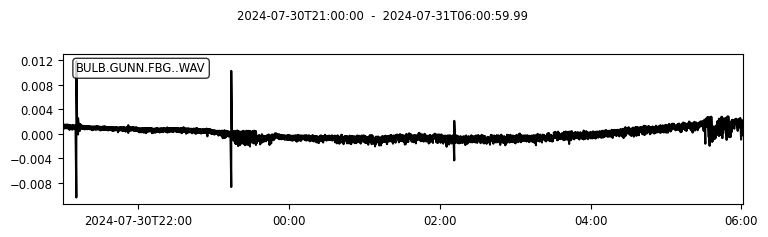

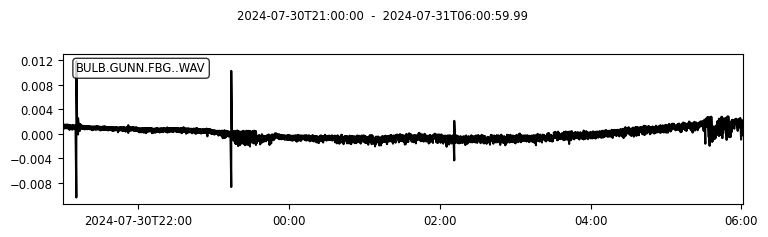

In [9]:
tr.detrend(type='linear')
tr.plot()

### Band-pass filter

In [10]:
tr2 = tr.filter('bandpass', freqmin=.5,freqmax=45).copy()

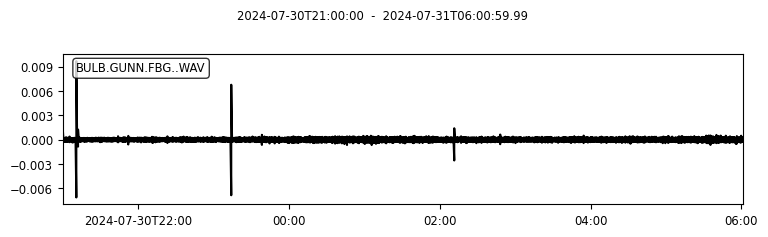

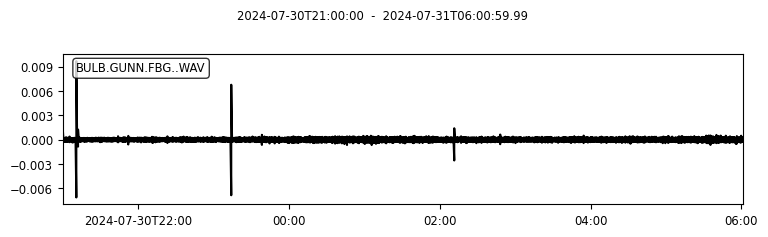

In [11]:
tr2.plot()

### Zoom on a specific event

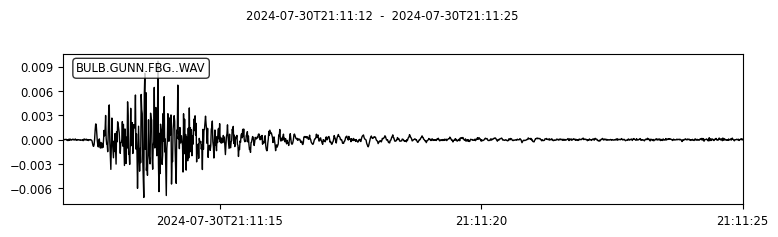

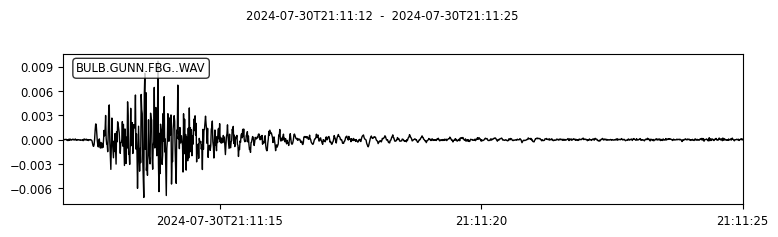

In [12]:
tr2.plot(starttime=tr.stats.starttime+11*60+12, endtime=tr.stats.starttime+11*60+25)

In [13]:
dc = tr2.copy().trim(starttime=tr2.stats.starttime+11*60+12, endtime=tr2.stats.starttime+11*60+30).data

## Processing broadband data

### Importing and merging files

In [14]:
files = path+'/broadband/*_4893z6_2024073*.msd'

In [15]:
bb = obspy.read(files)
bb = bb.merge()

### Clipping to the period of interest 

In [16]:
bb = bb.trim(starttime=tr2.stats.starttime, endtime=tr2.stats.endtime)

### Renaming the broadband to match with the response file

In [17]:
bb[0].stats.network = 'BE'
bb[0].stats.station = 'TST1'

In [18]:
bb

1 Trace(s) in Stream:
BE.TST1..HHZ | 2024-07-30T21:00:00.000000Z - 2024-07-31T06:00:59.990000Z | 100.0 Hz, 3246000 samples

In [19]:
inv = obspy.read_inventory("../data/response/TST1_3ESPCD_6000Vms_60s_100Hz.dataless.converted.xml")

In [20]:
inv

Inventory created at 2025-05-15T07:36:47.722624Z
	Created by: IRIS converter | version: 
		    https://seiscode.iris.washington.edu/projects/stationxml-...
	Sending institution: IRIS-DMC
	Contains:
		Networks (1):
			BE
		Stations (1):
			BE.TST1 (TST1 test station)
		Channels (3):
			BE.TST1..HHZ, BE.TST1..HHN, BE.TST1..HHE

### Apply the instrument response

In [21]:
pre_filt = [0.001, 0.005, 45, 50]


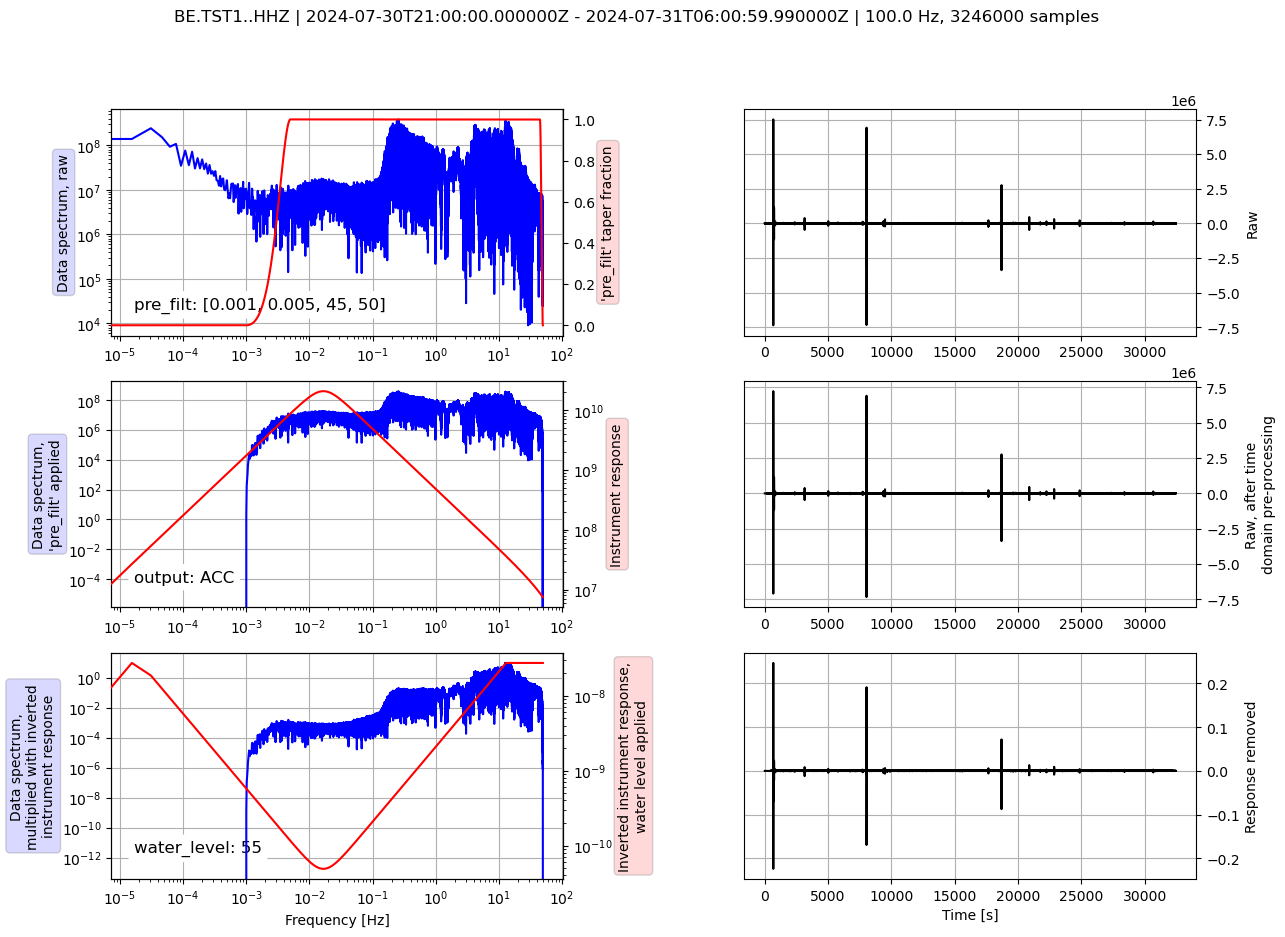

In [22]:
bb = bb.remove_response(inventory=inv, pre_filt=pre_filt, output="ACC",
                   water_level=55, plot=True)  

### Band-pass filter

In [23]:
bb = bb.filter('bandpass', freqmin=1,freqmax=45)

## Comparison between the two sensors

### Plot the two sensors

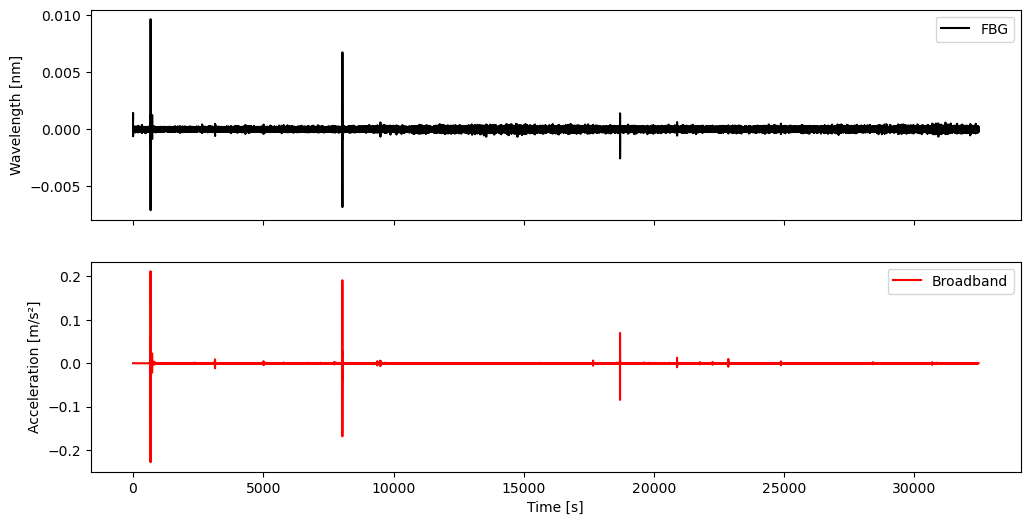

In [24]:
fig, ax = plt.subplots(2,1, figsize=(12,6), sharex=True)
ax[0].plot(tr2.times(), tr2.data, color='k', label='FBG')
ax[0].set_ylabel('Wavelength [nm]')
ax[1].plot(bb[0].times(), bb[0].data, color='r', label='Broadband')
ax[1].set_ylabel('Acceleration [m/s²]')
ax[1].set_xlabel('Time [s]')
ax[0].legend()
ax[1].legend()
plt.show()

### Importing earthquakes catalog

In [25]:
earthquake = pd.read_csv('../map/gunn_earthquake_30072024.csv')
etime = np.array(earthquake['time'])
etime = etime.astype('datetime64[s]')

### Plotting all the event with a magnitude superior to 1

2024-07-30T21:11:09.000000Z
2024-07-30T21:12:09.000000Z
2024-07-30T21:13:36.000000Z
2024-07-30T21:52:24.000000Z
2024-07-30T22:23:29.000000Z
2024-07-30T23:13:54.000000Z
2024-07-30T23:36:17.000000Z
2024-07-30T23:38:14.000000Z
2024-07-31T01:54:18.000000Z
2024-07-31T02:11:34.000000Z
2024-07-31T02:48:03.000000Z
2024-07-31T03:10:45.000000Z
2024-07-31T03:20:51.000000Z
2024-07-31T03:54:28.000000Z
2024-07-31T05:31:22.000000Z


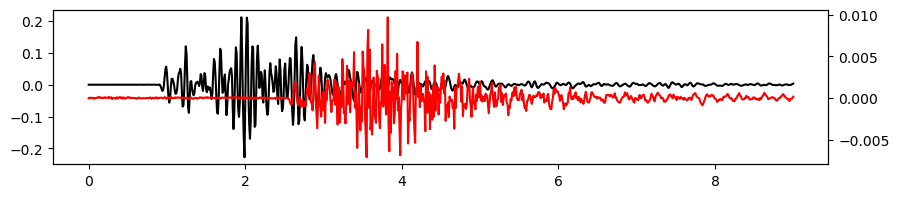

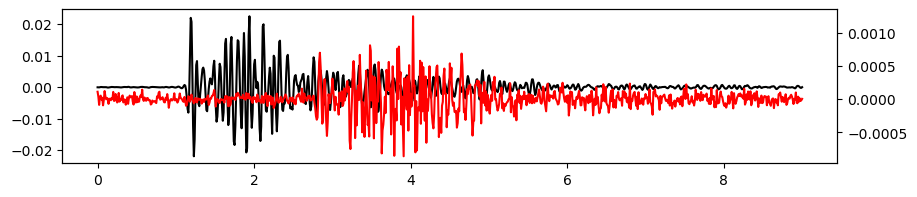

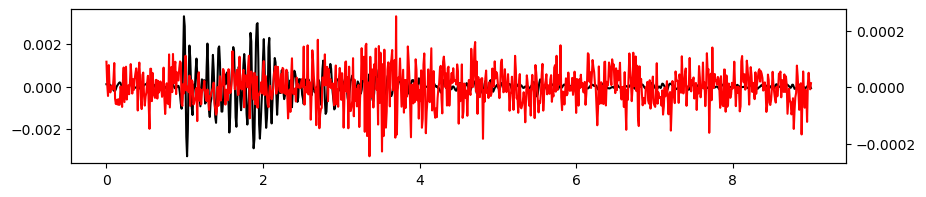

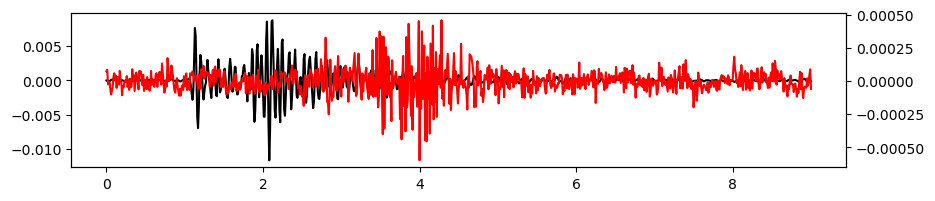

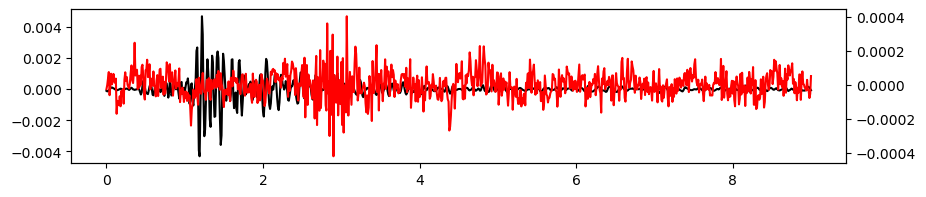

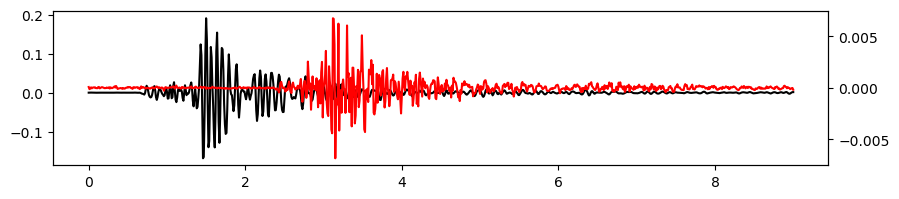

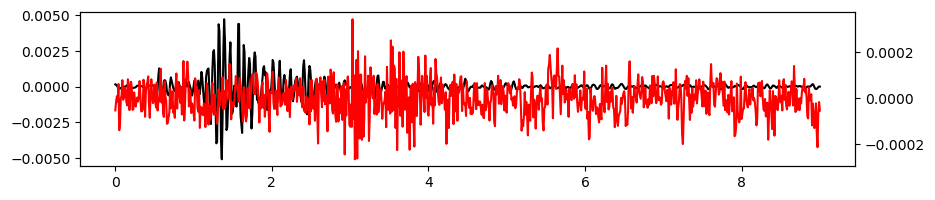

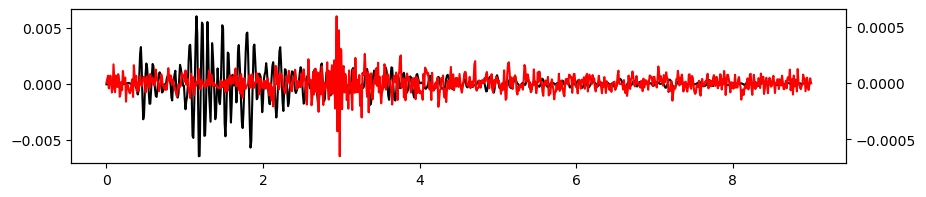

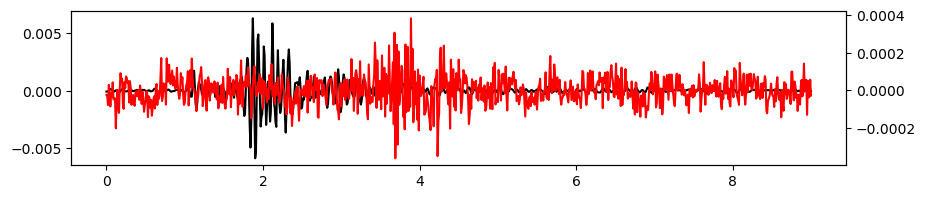

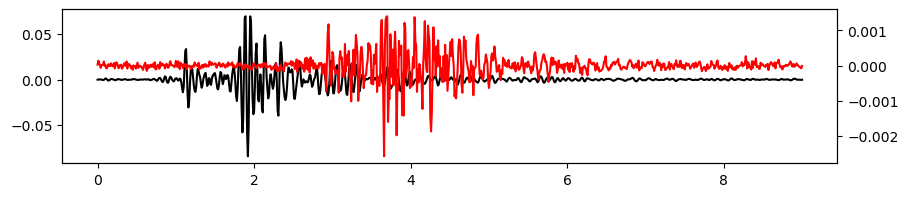

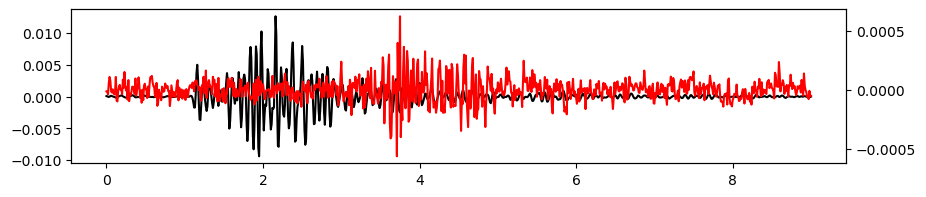

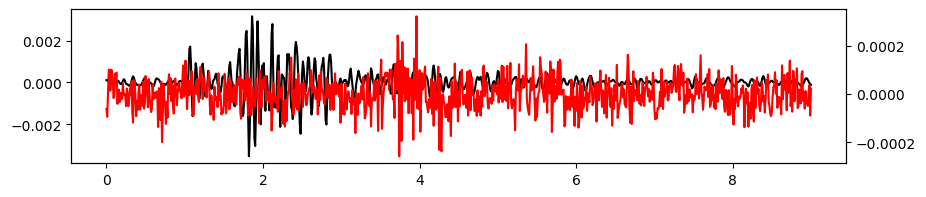

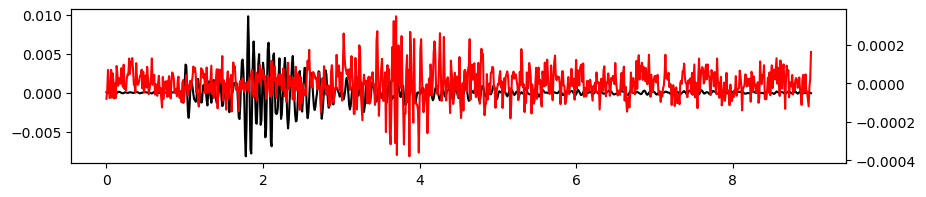

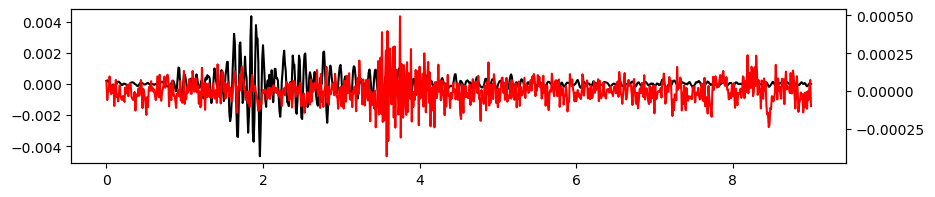

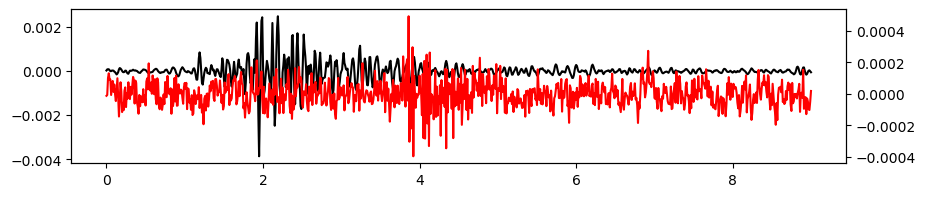

In [26]:
CC = []

for i in range(27):
    eq = earthquake.iloc[i]
    if eq.magnitude <1 :
        continue
    eqtime = obspy.UTCDateTime(eq.time)
    bb_tr = bb.copy().trim(starttime=eqtime+1, endtime=eqtime+10)
    fbg_tr = tr2.copy().trim(starttime=eqtime+1, endtime=eqtime+10)
    fig, ax = plt.subplots(figsize=(10, 2))
    ax.plot(bb_tr[0].times(), bb_tr[0].data, color='black', label='BB')
    ab = ax.twinx()
    ab.plot(fbg_tr.times(), fbg_tr.data, color='red', label='FBG')

    cc = correlate(bb_tr[0].data, fbg_tr.data)
    lags = correlation_lags(len(bb_tr[0].data), len(fbg_tr.data))/100
    CC.append(cc)

    print(eqtime)

### Find time lag between the 2 sensors

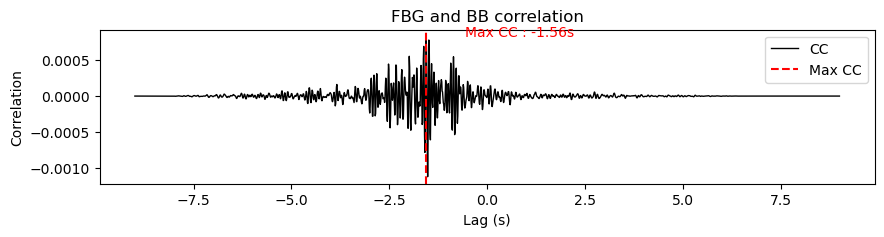

In [27]:
plt.figure(figsize=(10, 2))
plt.plot(lags, np.mean(np.array(CC), axis=0), color='black', linewidth=1, label='CC')
plt.axvline(lags[np.argmax(np.mean(np.array(CC), axis=0))], color='red', linestyle='--', label='Max CC')
plt.text(lags[np.argmax(np.mean(np.array(CC), axis=0))]+1, np.max(np.mean(np.array(CC), axis=0)), 'Max CC : %.2fs' %lags[np.argmax(np.mean(np.array(CC), axis=0))], color='red')
plt.xlabel('Lag (s)')
plt.ylabel('Correlation')
plt.title('FBG and BB correlation')
plt.legend()

lag_time = lags[np.argmax(np.mean(np.array(CC), axis=0))]-.1

### Correcting the time lag and plotting

2024-07-30T21:11:09.000000Z
2024-07-30T21:12:09.000000Z
2024-07-30T21:13:36.000000Z
2024-07-30T21:52:24.000000Z
2024-07-30T22:23:29.000000Z
2024-07-30T23:13:54.000000Z
2024-07-30T23:36:17.000000Z
2024-07-30T23:38:14.000000Z
2024-07-31T01:54:18.000000Z
2024-07-31T02:11:34.000000Z
2024-07-31T02:48:03.000000Z
2024-07-31T03:10:45.000000Z
2024-07-31T03:20:51.000000Z
2024-07-31T03:54:28.000000Z
2024-07-31T05:31:22.000000Z


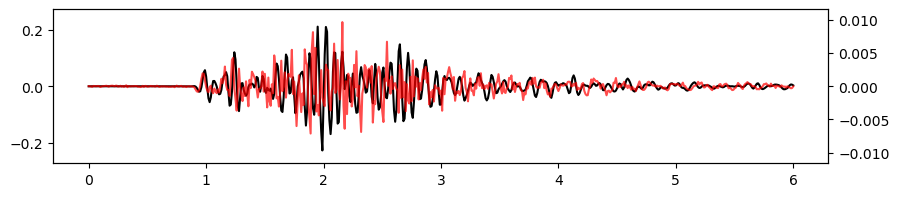

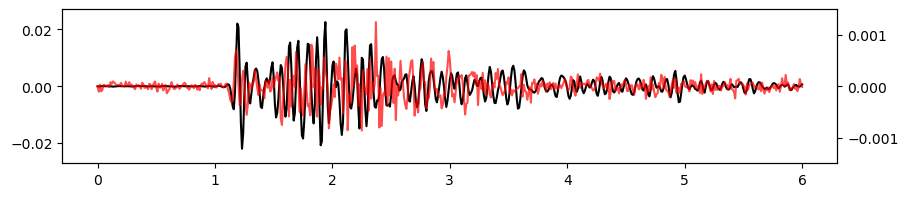

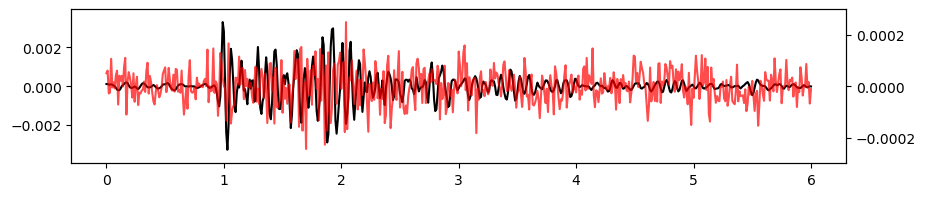

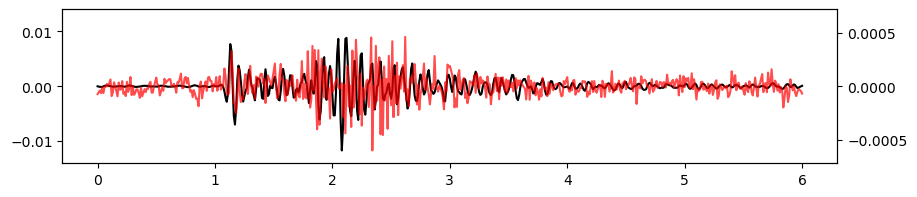

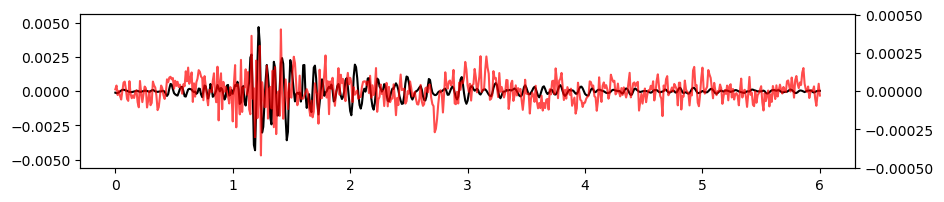

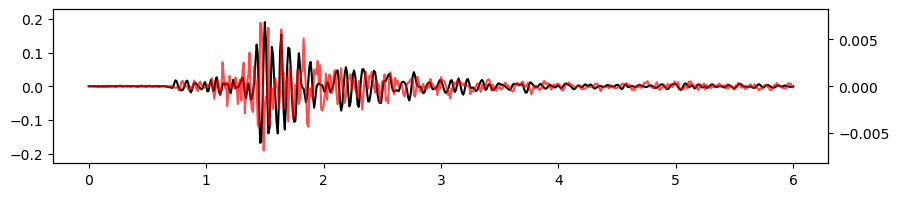

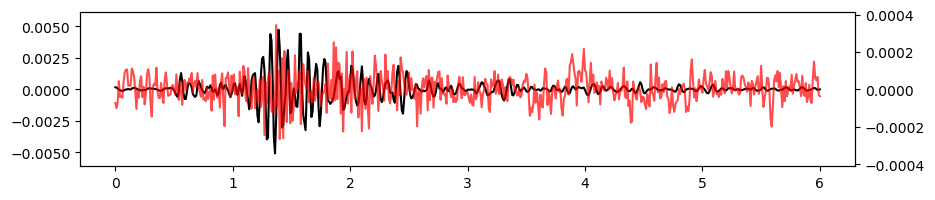

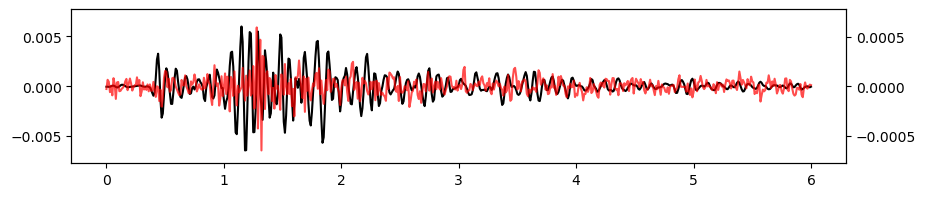

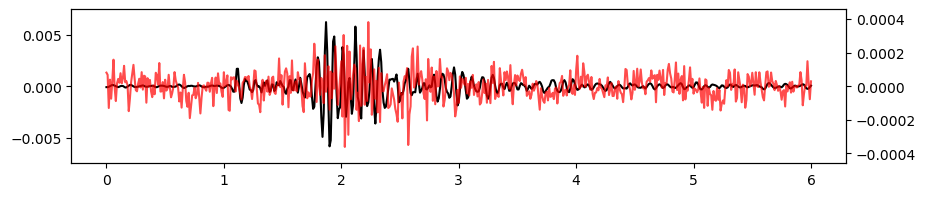

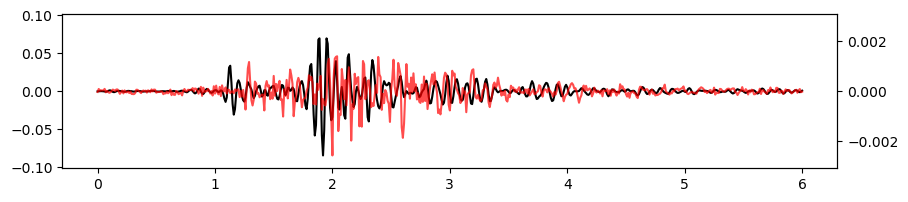

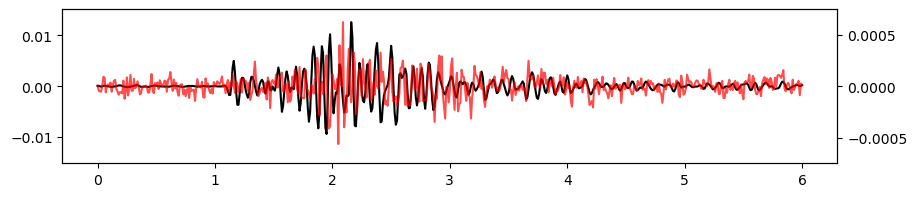

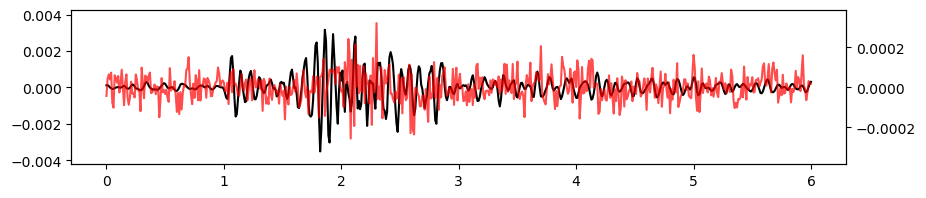

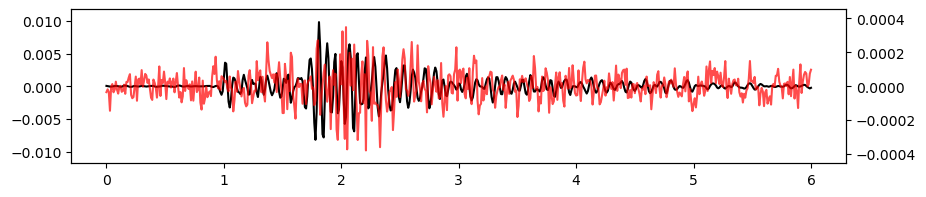

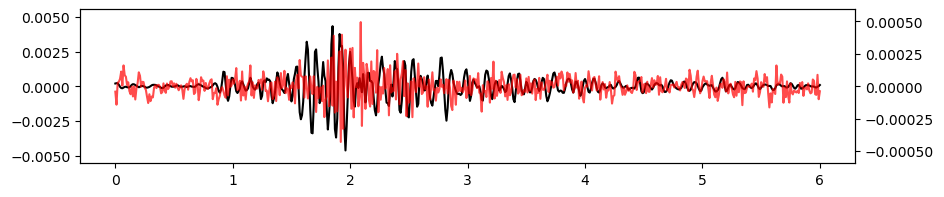

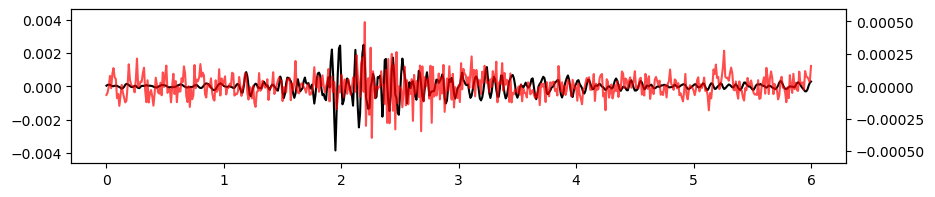

In [28]:
FFT_BB = []
FFT_FBG = []

rFFT_BB = []
rFFT_FBG = []

iFFT_BB = []
iFFT_FBG = []

for i in range(27):
    eq = earthquake.iloc[i]
    if eq.magnitude < 1:
        continue
    eqtime = obspy.UTCDateTime(eq.time)
    bb_tr = bb.copy().trim(starttime=eqtime+1, endtime=eqtime+7)
    fbg_tr = tr2.copy().trim(starttime=eqtime+1 - lag_time, endtime=eqtime+7- lag_time)

    FFT_BB.append(np.fft.fft(bb_tr[0].data))
    FFT_FBG.append(np.fft.fft(fbg_tr.data))
    rFFT_BB.append(np.fft.rfft(bb_tr[0].data))
    rFFT_FBG.append(np.fft.rfft(fbg_tr.data))

    freq = np.fft.fftfreq(len(bb_tr[0].data), 0.01)
    rfreq = np.fft.rfftfreq(len(bb_tr[0].data), 0.01)
    
    fig, ax = plt.subplots(figsize=(10, 2))
    ax.plot(bb_tr[0].times(), bb_tr[0].data, color='black', label='BB')
    ab = ax.twinx()
    ab.plot(fbg_tr.times(), fbg_tr.data, color='red', label='FBG', alpha=0.7)
    max_fbg, min_fbg = np.max(fbg_tr.data), np.min(fbg_tr.data)
    max_bb, min_bb = np.max(bb_tr[0].data), np.min(bb_tr[0].data)




    if np.abs(max_fbg) > np.abs(min_fbg):
        ab.set_ylim(-max_fbg*1.2, max_fbg*1.2)
    else:
        ab.set_ylim(min_fbg*1.2, -min_fbg*1.2)
    if np.abs(max_bb) > np.abs(min_bb):
        ax.set_ylim(-max_bb*1.2, max_bb*1.2)
    else :
        ax.set_ylim(min_bb*1.2, -min_bb*1.2)
    print(eqtime)

### Plotting the FFT of the first event

/tmp/ipykernel_564611/3854599602.py:13: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0,100)


(0.12510350150159302, 100)

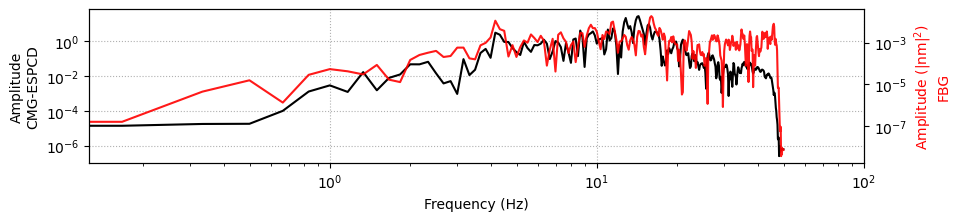

In [29]:
n =0 
fig, ax = plt.subplots(figsize=(10, 2))
ax.plot(rfreq, np.abs(rFFT_BB[n])**2, color='black', label='BB')
axb = ax.twinx()
axb.plot(rfreq, np.abs(rFFT_FBG[n])**2, color='red', label='FBG', alpha=0.9)
ax.set_yscale('log')
ax.grid(ls=':')
ax.set_ylabel('Amplitude\nCMG-ESPCD')
axb.set_yscale('log')
axb.set_ylabel('Amplitude (|nm|$^2$)\nFBG', c='red')
ax.set_xscale('log')
ax.set_xlabel('Frequency (Hz)')
ax.set_xlim(0,100)

### Find the conversion between between the 2 sensors

In [30]:
sensitivity = np.abs(rFFT_FBG)/np.abs(rFFT_BB)

### Plot the sensitivity curve and median value

(1.0, 50.0)

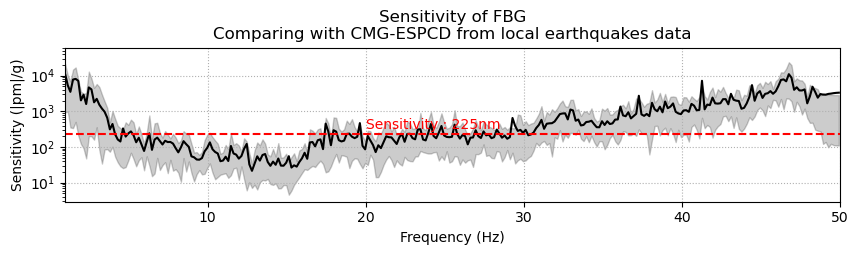

In [31]:
plt.figure(figsize=(10, 2))
plt.plot(rfreq, np.mean(sensitivity, axis=0)*1000, color='black', label='BB')
plt.fill_between(rfreq, np.percentile(sensitivity, 10, axis=0)*1000
                 , np.percentile(sensitivity, 90, axis=0)*1000, color='black', alpha=0.2)
plt.text(20, np.median(sensitivity)*1000+100, 'Sensitivity : %.0fnm' %(np.median(sensitivity)*1000), color='red')
plt.axhline(np.median(sensitivity)*1000, color='red', linestyle='--')

#plt.xscale('log')
plt.yscale('log')
plt.grid(ls=':')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Sensitivity (|pm|/g)')
plt.title('Sensitivity of FBG\nComparing with CMG-ESPCD from local earthquakes data')
plt.xlim(1, 50)

### Build a simple response curve

In [32]:
fft_ex = rFFT_FBG[0]
freq_ex = rfreq

In [33]:
arr_conv = np.full((len(fft_ex),), 1.8)
[0,6,20,50]
s1 = (1.8-3)/(8-1)
s2 = (3.5-1.8)/(50-15)
arr_conv = np.where(freq_ex < 8, s1*(freq_ex-1)+3, arr_conv)
arr_conv = np.where(freq_ex > 15, s2*(freq_ex-15)+1.8, arr_conv)

#nm2g = 

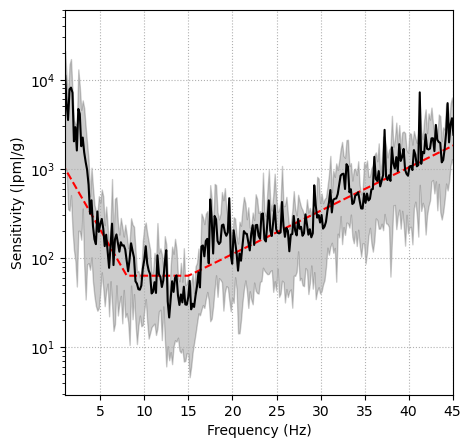

In [34]:
plt.figure(figsize=(5, 5))
plt.plot(freq_ex, 10**arr_conv, c='r', ls='--')
plt.plot(rfreq, np.mean(sensitivity, axis=0)*1000, color='black', label='BB')
plt.fill_between(rfreq, np.percentile(sensitivity, 10, axis=0)*1000
                 , np.percentile(sensitivity, 90, axis=0)*1000, color='black', alpha=0.2)
plt.grid(ls=':')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Sensitivity (|pm|/g)')
#plt.yscale('log')
plt.xlim(1, 45)
plt.yscale('log')

### Plot the 2 sensors before and after applying the simple response correction in amplitude

In [35]:
eq_r = np.fft.irfft(2*fft_ex/10**arr_conv*1000)
#eq_r = np.fft.irfft(convert*neg_pos)

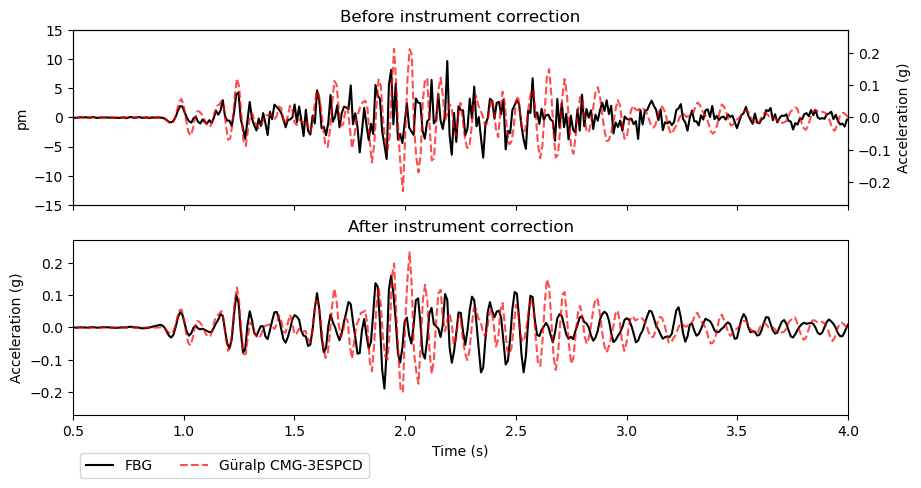

In [36]:
n = 0
fig, ax = plt.subplots(figsize=(10, 5), nrows=2, sharex=True)
eq = earthquake.iloc[n]
eqtime = obspy.UTCDateTime(eq.time)
fbg_tr = tr2.copy().trim(starttime=eqtime+1 - lag_time, endtime=eqtime+7- lag_time)
bb_tr = bb.copy().trim(starttime=eqtime+1, endtime=eqtime+7)


fbgplot = ax[0].plot(fbg_tr.times()+(fbg_tr.times()*0.014), fbg_tr.data*1000, label='FBG', color='black')
ax[0].set_ylim(-15,15)
axb = ax[0].twinx()
bbplot = axb.plot(bb_tr[0].times(), bb_tr[0].data, color='r', label='Güralp CMG-3ESPCD', ls='--', alpha=.7)
axb.set_ylabel('Acceleration (g)')
#ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('pm')
ax[0].set_title('Before instrument correction')
axb.set_ylim(-0.27, 0.27)



ax[1].plot(fbg_tr.times()[:-1]+(fbg_tr.times()[:-1]*0.014), eq_r, label='FBG', color='black')
ax[1].plot(bb_tr[0].times()[:-1], np.fft.irfft(rFFT_BB[n]), color='r', label='BB', ls='--', alpha=.7)
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Acceleration (g)')
ax[1].set_title('After instrument correction')
ax[1].set_xlim(0.5,4)
ax[1].set_ylim(-0.27, 0.27)
fig.legend(handles=[fbgplot[0], bbplot[0]], ncols=2, loc='lower left', bbox_to_anchor=(0, -1.6), bbox_transform=ax[0].transAxes)
plt.savefig('../plots/gunn_intrument_response.png', dpi=300, bbox_inches='tight')
plt.show()

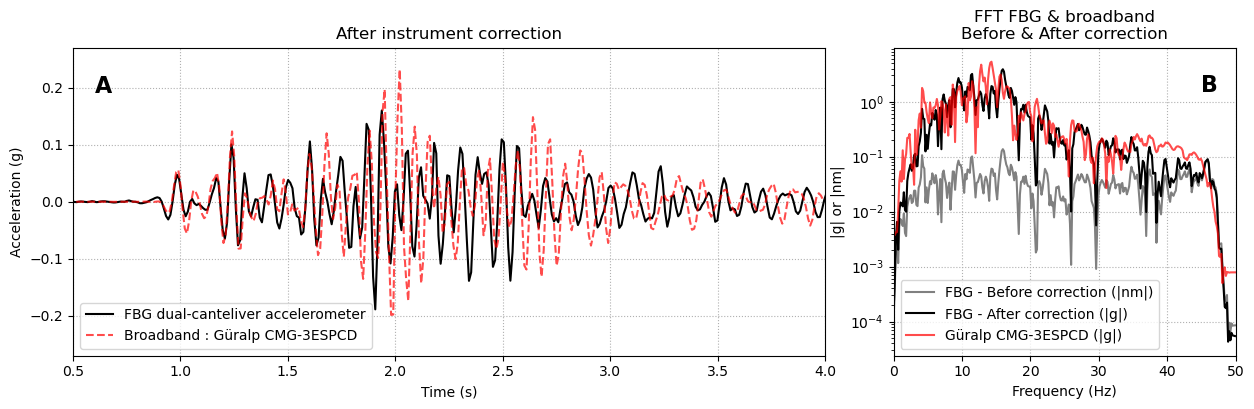

In [37]:
fig = plt.figure(figsize=(15, 4))
ax = plt.subplot2grid((1, 3), (0, 0), colspan=2)
ax.plot(fbg_tr.times()[:-1]+(fbg_tr.times()[:-1]*0.014), eq_r, label='FBG dual-canteliver accelerometer', color='black')
ax.plot(bb_tr[0].times()[:-1], np.fft.irfft(rFFT_BB[n]), color='r', label='Broadband : Güralp CMG-3ESPCD', ls='--', alpha=.7)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Acceleration (g)')
ax.set_title('After instrument correction')
ax.set_xlim(0.5,4)
ax.set_ylim(-0.27, 0.27)
ax.legend(loc='lower left')
ax.grid(ls=':')
ax2 = plt.subplot2grid((1, 3), (0, 2), colspan=1)
fbgbf = ax2.plot(freq_ex, np.abs(fft_ex), c='grey', label='FBG - Before correction (|nm|)')
fbgplot = ax2.plot(freq_ex, np.abs(2*fft_ex/10**arr_conv*1000), color='k', label='FBG - After correction (|g|)')
bbplot = ax2.plot(rfreq, np.abs(rFFT_BB[n]), color='r', label='Güralp CMG-3ESPCD (|g|)',alpha=0.7)
ax2.set_xlim(0, 50)
ax2.set_yscale('log')
ax2.grid(ls=':')
ax2.set_ylabel('|g| or |nm|')
ax2.set_xlabel('Frequency (Hz)')
ax2.set_title('FFT FBG & broadband\nBefore & After correction')
ax.text(0.6,0.19, 'A', fontsize=16, fontweight='bold',)
ax2.text(45,1.5, 'B', fontsize=16, fontweight='bold',)
ax2.legend(loc='lower left')
plt.savefig('../plots/gunn_comparison.png', dpi=300, bbox_inches='tight')

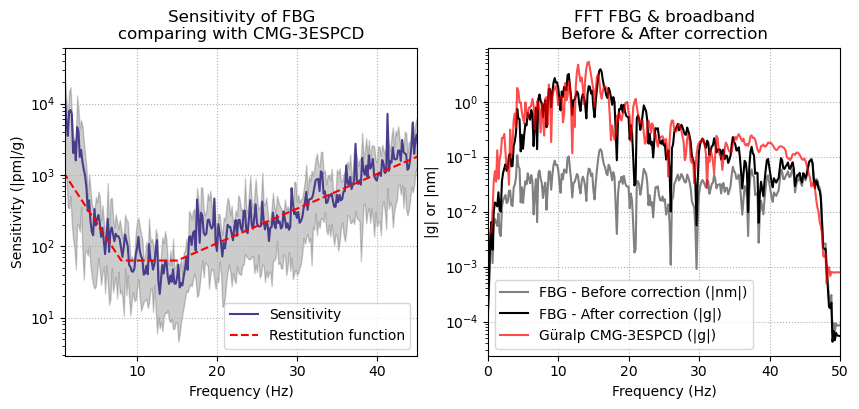

In [38]:
fig, ax = plt.subplots(figsize=(10, 4), ncols=2)



ax[0].plot(rfreq, np.mean(sensitivity, axis=0)*1000, color='darkslateblue', label='Sensitivity')
ax[0].plot(freq_ex, 10**arr_conv, c='r', ls='--', label='Restitution function')
ax[0].fill_between(rfreq, np.percentile(sensitivity, 10, axis=0)*1000
                 , np.percentile(sensitivity, 90, axis=0)*1000, color='black', alpha=0.2)
ax[0].grid(ls=':')
ax[0].set_xlabel('Frequency (Hz)')
ax[0].set_ylabel('Sensitivity (|pm|/g)')
ax[0].set_title('Sensitivity of FBG\ncomparing with CMG-3ESPCD')
ax[0].set_yscale('log')
ax[0].legend(loc='lower right')
ax[0].set_xlim(1, 45)




fbgbf = ax[1].plot(freq_ex, np.abs(fft_ex), c='grey', label='FBG - Before correction (|nm|)')
fbgplot = ax[1].plot(freq_ex, np.abs(2*fft_ex/10**arr_conv*1000), color='k', label='FBG - After correction (|g|)')
bbplot = ax[1].plot(rfreq, np.abs(rFFT_BB[n]), color='r', label='Güralp CMG-3ESPCD (|g|)',alpha=0.7)
ax[1].set_xlim(0, 50)
ax[1].set_yscale('log')
ax[1].grid(ls=':')
ax[1].set_ylabel('|g| or |nm|')
ax[1].set_title('FFT FBG & broadband\nBefore & After correction')

ax[1].set_xlabel('Frequency (Hz)')
ax[0].set_xlabel('Frequency (Hz)')
ax[1].legend(loc='lower left')
plt.savefig('../plots/gunn_instrument_response_fft.png', dpi=300, bbox_inches='tight')
plt.show()
